# Notebook 09: Mapeos Cuántico-Compatibles

## Objetivo
Si un dataset no tiene estructura cuántica nativa, ¿puede transformarse a un espacio de representación donde sí la tenga, **sin alterar la información discriminativa**?

## Metodología
1. **Literatura**: implementar las estrategias de pre-mapeo propuestas en Lloyd et al. (2020), Pérez-Salinas et al. (2020), Haug et al. (2023) y Havlíček et al. (2019)
2. **Aplicación**: aplicar cada estrategia sobre SKG Incidentes y Telco Churn (datasets sin ventaja cuántica)
3. **Evaluación**: medir si el pre-mapeo incrementa Q(D), ΔA, d_F y la ventaja empírica del QSVM
4. **Análisis**: ¿qué estrategia funciona mejor y por qué?
5. **Propuesta**: Framework QCR (Quantum-Compatible Representation) de 4 pasos

## Estrategias implementadas
| Estrategia | Referencia | Idea |
|-----------|-----------|------|
| Features ZZ-compatible | Havlíček et al. (2019) | Añadir productos cruzados $x_j(\pi - x_k)$ que el ZZFeatureMap explota |
| Rotación de máx. divergencia | Liu et al. (2021) | Buscar $R \in O(d)$ que maximice $d_F(K_Q(Rx), K_{RBF}(Rx))$ |
| Re-uploading adaptativo | Pérez-Salinas et al. (2020) | Repetir la codificación de datos en múltiples capas del circuito |
| UMAP con métrica cuántica | Haug et al. (2023) | Reducción dimensional preservando distancias cuánticas |

## §1 — Imports y reutilización de funciones del NB08

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize, minimize_scalar
from scipy.spatial.distance import cdist
from scipy.linalg import expm
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

import sys, os
BASE    = '/Users/juanprada/Documents/TFM_ComputacionCuantica'
FIGURES = f'{BASE}/POCs/data/output/figures'
METRICS = f'{BASE}/POCs/data/output/metrics'
DATA    = f'{BASE}/Datos'
os.makedirs(FIGURES, exist_ok=True)
os.makedirs(METRICS, exist_ok=True)

np.random.seed(42)
plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 11,
    'axes.titlesize': 12, 'axes.labelsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
})
print('✅ Imports estándar OK')


✅ Imports estándar OK


In [2]:
# ── Imports Qiskit (celda separada — puede tardar 20-60s la primera vez) ──────
print('Cargando Qiskit...', end=' ', flush=True)
from qiskit.circuit.library import ZZFeatureMap
from qiskit_machine_learning.kernels import FidelityQuantumKernel
print('✅ Qiskit OK')


Cargando Qiskit... ✅ Qiskit OK


In [3]:
# ── Funciones reutilizadas del NB08 (puro NumPy/sklearn — ejecución inmediata) ─
def kernel_alignment(K, y):
    y = np.array(y, dtype=float)
    Ky = np.outer(y, y)
    num = np.sum(K * Ky)
    den = np.linalg.norm(K, 'fro') * np.linalg.norm(Ky, 'fro')
    return float(num / den) if den > 1e-12 else 0.0

def spectral_entropy(K):
    eigenvalues = np.maximum(np.real(np.linalg.eigvalsh(K)), 0)
    s = eigenvalues.sum()
    if s < 1e-12: return 0.0
    lam = eigenvalues / s
    lam = lam[lam > 1e-15]
    return float(-np.sum(lam * np.log(lam)))

def best_rbf_kernel(X, K_Q):
    dists_sq = cdist(X, X, 'sqeuclidean')
    def obj(log_s):
        K_rbf = np.exp(-dists_sq / (2 * np.exp(log_s)**2))
        return np.linalg.norm(K_Q - K_rbf, 'fro')
    res = minimize_scalar(obj, bounds=(-3, 3), method='bounded')
    sigma_opt = np.exp(res.x)
    K_rbf_opt = np.exp(-dists_sq / (2 * sigma_opt**2))
    return K_rbf_opt, sigma_opt

def frobenius_distance(K_Q, K_cl):
    return float(np.linalg.norm(K_Q - K_cl, 'fro') / K_Q.shape[0])

def quantumness_score(A_Q, A_cl, d_F, H_Q, H_cl, d_F_ref=1.0, w=(0.4, 0.3, 0.3)):
    dA = A_Q - A_cl
    d_F_norm = d_F / max(d_F_ref, 1e-12)
    dH = H_Q - H_cl
    return float(w[0]*dA + w[1]*d_F_norm + w[2]*dH)

print('✅ Funciones helper OK')
print(f'   BASE: {BASE}')


✅ Funciones helper OK
   BASE: /Users/juanprada/Documents/TFM_ComputacionCuantica


## §2 — Carga de datasets y cálculo de indicadores BASELINE (sin pre-mapeo)

In [4]:
def preprocess_dataset(X_raw, y_raw, n_sample=80, n_qubits=2, seed=42):
    """Escala, PCA a n_qubits dims, normaliza a [-π,π], submuestrea estratificado."""
    y_arr = np.where(np.array(y_raw) == 0, -1, 1).astype(float)
    X_sc  = StandardScaler().fit_transform(X_raw)
    X_pca = PCA(n_components=n_qubits).fit_transform(X_sc)
    X_norm = MinMaxScaler(feature_range=(-np.pi, np.pi)).fit_transform(X_pca)
    if len(X_norm) > n_sample:
        from sklearn.model_selection import StratifiedShuffleSplit
        sss = StratifiedShuffleSplit(1, train_size=n_sample, random_state=seed)
        idx, _ = next(sss.split(X_norm, y_arr))
        X_norm, y_arr = X_norm[idx], y_arr[idx]
    return X_norm, y_arr

def eval_qsvm_advantage(X, y_arr, qkernel, sigma):
    """Calcula ventaja empírica QSVM vs SVM-RBF en una split 70/30."""
    X_tr, X_te, y_tr, y_te = train_test_split(X, y_arr, test_size=0.3, random_state=42, stratify=y_arr)
    K_Q_tr  = qkernel.evaluate(X_tr)
    K_Q_te  = qkernel.evaluate(X_te, X_tr)
    K_cl_tr = rbf_kernel(X_tr, gamma=1/(2*sigma**2))
    K_cl_te = rbf_kernel(X_te, X_tr, gamma=1/(2*sigma**2))
    acc_Q  = SVC(kernel='precomputed', C=1.0).fit(K_Q_tr, y_tr).score(K_Q_te, y_te)
    acc_cl = SVC(kernel='precomputed', C=1.0).fit(K_cl_tr, y_tr).score(K_cl_te, y_te)
    return acc_Q*100, acc_cl*100, (acc_Q - acc_cl)*100

def compute_indicators(X, y_arr, qkernel, label=''):
    """Calcula todos los indicadores de cuanticidad sobre X, y_arr."""
    K_Q = qkernel.evaluate(X)
    K_rbf, sigma = best_rbf_kernel(X, K_Q)
    A_Q  = kernel_alignment(K_Q, y_arr)
    A_cl = kernel_alignment(K_rbf, y_arr)
    H_Q  = spectral_entropy(K_Q)
    H_cl = spectral_entropy(K_rbf)
    dF   = frobenius_distance(K_Q, K_rbf)
    Q    = quantumness_score(A_Q, A_cl, dF, H_Q, H_cl)
    acc_Q, acc_cl, adv = eval_qsvm_advantage(X, y_arr, qkernel, sigma)
    return {
        'label': label, 'A_Q': A_Q, 'A_cl': A_cl, 'delta_A': A_Q - A_cl,
        'H_Q': H_Q, 'H_cl': H_cl, 'delta_H': H_Q - H_cl,
        'd_F': dF, 'Q_score': Q,
        'acc_QSVM': acc_Q, 'acc_SVM': acc_cl, 'advantage_pp': adv,
        '_K_Q': K_Q, '_K_rbf': K_rbf, '_sigma': sigma
    }

# ── Inicializar kernel cuántico ───────────────────────────────────────────────
fm = ZZFeatureMap(feature_dimension=2, reps=2)
qk = FidelityQuantumKernel(feature_map=fm)

# ── Cargar y preprocesar SKG Incidentes ───────────────────────────────────────
print('Cargando SKG Incidentes...', end=' ')
df_skg = pd.read_csv(f'{DATA}/incidents_movility.csv')
target_skg = [c for c in df_skg.columns if any(k in c.lower() for k in ['gravity','grave','severity','fatal','clase'])]
target_skg = target_skg[0] if target_skg else df_skg.columns[-1]
top2 = df_skg[target_skg].value_counts().index[:2]
df_skg_b = df_skg[df_skg[target_skg].isin(top2)].copy()
y_skg_raw = LabelEncoder().fit_transform(df_skg_b[target_skg])
X_skg_raw = df_skg_b.drop(columns=[target_skg])
for c in X_skg_raw.select_dtypes('object').columns:
    X_skg_raw[c] = LabelEncoder().fit_transform(X_skg_raw[c].astype(str))
X_skg_r = SimpleImputer(strategy='median').fit_transform(X_skg_raw)
X_skg, y_skg = preprocess_dataset(X_skg_r, y_skg_raw)
print(f'OK — n={len(X_skg)}')

# ── Cargar y preprocesar Telco Churn ─────────────────────────────────────────
print('Cargando Telco Churn...', end=' ')
df_telco = pd.read_csv(f'{BASE}/Ejemplos/h&k_PruebaTecnica/data/telco_churn.csv')
y_telco_raw = (df_telco['Churn'] == 'Yes').astype(int).values
X_telco_raw = df_telco.drop(columns=['Churn', 'customerID'], errors='ignore').copy()
for c in X_telco_raw.select_dtypes('object').columns:
    X_telco_raw[c] = LabelEncoder().fit_transform(X_telco_raw[c].astype(str))
if 'TotalCharges' in X_telco_raw.columns:
    X_telco_raw['TotalCharges'] = pd.to_numeric(X_telco_raw['TotalCharges'], errors='coerce')
X_telco_r = SimpleImputer(strategy='median').fit_transform(X_telco_raw)
X_telco, y_telco = preprocess_dataset(X_telco_r, y_telco_raw)
print(f'OK — n={len(X_telco)}')

# ── Calcular indicadores BASELINE ────────────────────────────────────────────
print('\nCalculando indicadores BASELINE (sin pre-mapeo)...')
baseline_skg   = compute_indicators(X_skg,   y_skg,   qk, label='SKG — baseline')
baseline_telco = compute_indicators(X_telco, y_telco, qk, label='Telco — baseline')

for r in [baseline_skg, baseline_telco]:
    print(f"\n{r['label']}:")
    print(f"  Q={r['Q_score']:+.4f}  ΔA={r['delta_A']:+.4f}  d_F={r['d_F']:.4f}  Adv={r['advantage_pp']:+.1f}pp")

# ── Estructuras compartidas por todas las estrategias ────────────────────────
# IMPORTANTE: definir aquí para que estén disponibles en todas las celdas siguientes
all_results = {'SKG Incidentes': [], 'Telco Churn': []}
datasets_eval = [
    ('SKG Incidentes', X_skg,   y_skg,   baseline_skg),
    ('Telco Churn',    X_telco, y_telco, baseline_telco),
]

print('\n✅ Baseline calculado  |  datasets_eval y all_results inicializados')


Cargando SKG Incidentes... OK — n=80
Cargando Telco Churn... OK — n=80

Calculando indicadores BASELINE (sin pre-mapeo)...

SKG — baseline:
  Q=+0.1629  ΔA=-0.0103  d_F=0.3689  Adv=+8.3pp

Telco — baseline:
  Q=-0.2277  ΔA=+0.0201  d_F=0.3457  Adv=+0.0pp

✅ Baseline calculado  |  datasets_eval y all_results inicializados


## §3 — Estrategia 1: Features de interacción ZZFeatureMap-compatible

**Base teórica** (Havlíček et al. 2019): el kernel del ZZFeatureMap tiene la forma analítica:
$$K_Q(x, x') \propto \prod_{j<k} \phi_{jk}(x)\phi_{jk}(x'), \quad \phi_{jk}(x) = x_j(\pi - x_k)$$

Si añadimos como feature adicional el término de interacción $z_{12} = x_1(\pi - x_2)$, el espacio clásico de entrada se alinea con la estructura aritmética que el ZZFeatureMap explota. Hipótesis: esto incrementará $A(K_Q, K_y)$ y $d_F$.

In [5]:
def apply_zz_features(X_norm):
    """
    Estrategia 1: Añadir features de interacción compatibles con ZZFeatureMap.
    Para cada par (j, k): z_jk = x_j * (pi - x_k)
    Las nuevas features se escalan a [-pi, pi] y se proyectan de vuelta a 2D con PCA.
    Ref: Havlíček et al. (2019) — ZZFeatureMap kernel structure.
    """
    n, d = X_norm.shape
    interaction_cols = []
    for j in range(d):
        for k in range(d):
            if j != k:
                z = X_norm[:, j] * (np.pi - X_norm[:, k])
                interaction_cols.append(z.reshape(-1, 1))
    X_aug = np.hstack([X_norm] + interaction_cols)
    X_back = PCA(n_components=2).fit_transform(X_aug)
    X_back = MinMaxScaler(feature_range=(-np.pi, np.pi)).fit_transform(X_back)
    return X_back

print('Estrategia 1: Features ZZ-compatible')
print('─' * 50)

for ds_name, X, y_arr, baseline in datasets_eval:
    X_mapped = apply_zz_features(X)
    r = compute_indicators(X_mapped, y_arr, qk, label=f'{ds_name} — ZZ-compat')
    r['strategy'] = 'ZZ-compatible'
    r['dataset']  = ds_name
    all_results[ds_name].append(r)

    dQ   = r['Q_score']    - baseline['Q_score']
    dAdv = r['advantage_pp'] - baseline['advantage_pp']
    print(f"\n{ds_name}:")
    print(f"  Q: {baseline['Q_score']:+.4f} → {r['Q_score']:+.4f}  (Δ={dQ:+.4f}) {'✅' if dQ>0 else '❌'}")
    print(f"  Ventaja: {baseline['advantage_pp']:+.1f}pp → {r['advantage_pp']:+.1f}pp  (Δ={dAdv:+.1f}pp) {'✅' if dAdv>0 else '❌'}")

print('\n✅ Estrategia 1 completada')


Estrategia 1: Features ZZ-compatible
──────────────────────────────────────────────────

SKG Incidentes:
  Q: +0.1629 → -0.2033  (Δ=-0.3663) ❌
  Ventaja: +8.3pp → +12.5pp  (Δ=+4.2pp) ✅

Telco Churn:
  Q: -0.2277 → +0.1360  (Δ=+0.3636) ✅
  Ventaja: +0.0pp → +4.2pp  (Δ=+4.2pp) ✅

✅ Estrategia 1 completada


## §4 — Estrategia 2: Rotación ortogonal de máxima divergencia cuántico-clásica

**Base teórica** (Liu et al. 2021): la ventaja requiere que $K_Q \neq K_{cl}$. Si buscamos la rotación $R \in O(2)$ que **maximiza** $d_F(K_Q(Rx), K_{RBF}(Rx))$, reorganizamos los datos para que el ZZFeatureMap opere en la región del espacio de Hilbert más alejada del kernel RBF.

La rotación 2D queda parametrizada por un único ángulo $\theta \in [0, 2\pi)$.

In [6]:
def apply_rotation_max_divergence(X, y_arr, qk, n_angles=36, verbose=True):
    """
    Estrategia 2: Barrido de rotaciones 2D para maximizar d_F(K_Q(Rx), K_RBF(Rx)).
    Devuelve el X rotado con la rotación óptima y los resultados del barrido.
    Ref: Liu et al. (2021) — condición de no-aproximabilidad clásica.
    """
    thetas = np.linspace(0, np.pi, n_angles)  # solo [0,π] por simetría
    dFs, Q_scores = [], []

    for theta in thetas:
        R = np.array([[np.cos(theta), -np.sin(theta)],
                      [np.sin(theta),  np.cos(theta)]])
        X_rot = X @ R.T
        X_rot = MinMaxScaler(feature_range=(-np.pi, np.pi)).fit_transform(X_rot)
        K_Q   = qk.evaluate(X_rot)
        K_rbf, _ = best_rbf_kernel(X_rot, K_Q)
        dF = frobenius_distance(K_Q, K_rbf)
        A_Q  = kernel_alignment(K_Q, y_arr)
        A_cl = kernel_alignment(K_rbf, y_arr)
        H_Q  = spectral_entropy(K_Q)
        H_cl = spectral_entropy(K_rbf)
        Q    = quantumness_score(A_Q, A_cl, dF, H_Q, H_cl)
        dFs.append(dF)
        Q_scores.append(Q)

    best_idx   = np.argmax(Q_scores)
    best_theta = thetas[best_idx]
    R_best = np.array([[np.cos(best_theta), -np.sin(best_theta)],
                       [np.sin(best_theta),  np.cos(best_theta)]])
    X_best = X @ R_best.T
    X_best = MinMaxScaler(feature_range=(-np.pi, np.pi)).fit_transform(X_best)

    if verbose:
        print(f"  θ_opt = {np.degrees(best_theta):.1f}°  →  Q_max = {max(Q_scores):+.4f}  d_F_max = {max(dFs):.4f}")

    return X_best, thetas, dFs, Q_scores, best_theta

print('Estrategia 2: Rotación de máxima divergencia cuántico-clásica')
print('─' * 60)

rotation_details = {}
for ds_name, X, y_arr, baseline in datasets_eval:
    print(f"\n{ds_name}:")
    X_mapped, thetas, dFs, Q_scores, theta_opt = apply_rotation_max_divergence(X, y_arr, qk)
    r = compute_indicators(X_mapped, y_arr, qk, label=f'{ds_name} — Rotación')
    r['strategy'] = 'Rotación max-dF'
    r['dataset']  = ds_name
    all_results[ds_name].append(r)
    rotation_details[ds_name] = {'thetas': thetas, 'dFs': dFs, 'Q_scores': Q_scores, 'theta_opt': theta_opt}

    dQ   = r['Q_score']    - baseline['Q_score']
    dAdv = r['advantage_pp'] - baseline['advantage_pp']
    sign_Q   = '✅' if dQ   > 0 else '❌'
    sign_adv = '✅' if dAdv > 0 else '❌'
    print(f"  Q: {baseline['Q_score']:+.4f} → {r['Q_score']:+.4f}  (Δ={dQ:+.4f}) {sign_Q}")
    print(f"  Ventaja: {baseline['advantage_pp']:+.1f}pp → {r['advantage_pp']:+.1f}pp  (Δ={dAdv:+.1f}pp) {sign_adv}")

print('\n✅ Estrategia 2 completada')

Estrategia 2: Rotación de máxima divergencia cuántico-clásica
────────────────────────────────────────────────────────────

SKG Incidentes:
  θ_opt = 154.3°  →  Q_max = +0.1698  d_F_max = 0.3777
  Q: +0.1629 → +0.1698  (Δ=+0.0069) ✅
  Ventaja: +8.3pp → +0.0pp  (Δ=-8.3pp) ❌

Telco Churn:
  θ_opt = 92.6°  →  Q_max = +0.0956  d_F_max = 0.4006
  Q: -0.2277 → +0.0956  (Δ=+0.3233) ✅
  Ventaja: +0.0pp → +4.2pp  (Δ=+4.2pp) ✅

✅ Estrategia 2 completada


## §5 — Estrategia 3: Data re-uploading adaptativo

**Base teórica** (Pérez-Salinas et al. 2020): re-cargar los datos en múltiples capas del circuito equivale a usar un kernel que es **suma de kernels** del feature map base. Esto incrementa la expresividad sin añadir qubits. Implementamos el efecto clásicamente: generamos representaciones con `reps ∈ {1, 2, 3, 4}` del ZZFeatureMap y seleccionamos el `reps` que maximiza Q(D) sobre el dataset.

In [7]:
def apply_reuploading_sweep(X, y_arr, reps_list=[1, 2, 3, 4], verbose=True):
    """
    Estrategia 3: Barrido de reps del ZZFeatureMap (data re-uploading).
    Selecciona el número de repeticiones que maximiza Q(D).
    Ref: Pérez-Salinas et al. (2020) — data re-uploading for a universal quantum classifier.
    """
    results_sweep = []
    for reps in reps_list:
        fm_r = ZZFeatureMap(feature_dimension=2, reps=reps)
        qk_r = FidelityQuantumKernel(feature_map=fm_r)
        K_Q  = qk_r.evaluate(X)
        K_rbf, sigma = best_rbf_kernel(X, K_Q)
        A_Q  = kernel_alignment(K_Q, y_arr)
        A_cl = kernel_alignment(K_rbf, y_arr)
        H_Q  = spectral_entropy(K_Q)
        H_cl = spectral_entropy(K_rbf)
        dF   = frobenius_distance(K_Q, K_rbf)
        Q    = quantumness_score(A_Q, A_cl, dF, H_Q, H_cl)
        acc_Q, acc_cl, adv = eval_qsvm_advantage(X, y_arr, qk_r, sigma)
        results_sweep.append({
            'reps': reps, 'Q_score': Q, 'advantage_pp': adv,
            'A_Q': A_Q, 'A_cl': A_cl, 'delta_A': A_Q - A_cl,
            'H_Q': H_Q, 'H_cl': H_cl, 'delta_H': H_Q - H_cl,
            'd_F': dF, 'acc_QSVM': acc_Q, 'acc_SVM': acc_cl,
            '_qk': qk_r
        })
        if verbose:
            print(f"  reps={reps}: Q={Q:+.4f}  Adv={adv:+.1f}pp")

    best = max(results_sweep, key=lambda x: x['Q_score'])
    return best, results_sweep

print('Estrategia 3: Data re-uploading adaptativo (barrido de reps)')
print('─' * 60)

reuploading_details = {}
for ds_name, X, y_arr, baseline in datasets_eval:
    print(f"\n{ds_name}:")
    best_r, sweep_r = apply_reuploading_sweep(X, y_arr)
    reuploading_details[ds_name] = sweep_r

    r = {
        'label':       f'{ds_name} — Re-uploading (reps={best_r["reps"]})',
        'strategy':    f'Re-uploading reps={best_r["reps"]}',
        'dataset':     ds_name,
        'Q_score':     best_r['Q_score'],
        'advantage_pp': best_r['advantage_pp'],
        'A_Q':         best_r['A_Q'],
        'A_cl':        best_r['A_cl'],
        'delta_A':     best_r['delta_A'],
        'H_Q':         best_r['H_Q'],
        'H_cl':        best_r['H_cl'],
        'delta_H':     best_r['delta_H'],
        'd_F':         best_r['d_F'],
        'acc_QSVM':    best_r['acc_QSVM'],
        'acc_SVM':     best_r['acc_SVM'],
    }
    all_results[ds_name].append(r)

    dQ   = best_r['Q_score']    - baseline['Q_score']
    dAdv = best_r['advantage_pp'] - baseline['advantage_pp']
    sign_Q   = '✅' if dQ   > 0 else '❌'
    sign_adv = '✅' if dAdv > 0 else '❌'
    print(f"  Mejor reps={best_r['reps']}: Q={best_r['Q_score']:+.4f}  Adv={best_r['advantage_pp']:+.1f}pp")
    print(f"  Q: {baseline['Q_score']:+.4f} → {best_r['Q_score']:+.4f}  (Δ={dQ:+.4f}) {sign_Q}")
    print(f"  Ventaja: {baseline['advantage_pp']:+.1f}pp → {best_r['advantage_pp']:+.1f}pp  (Δ={dAdv:+.1f}pp) {sign_adv}")

print('\n✅ Estrategia 3 completada')


Estrategia 3: Data re-uploading adaptativo (barrido de reps)
────────────────────────────────────────────────────────────

SKG Incidentes:
  reps=1: Q=-0.2982  Adv=+8.3pp
  reps=2: Q=+0.1629  Adv=+8.3pp
  reps=3: Q=+0.2118  Adv=+16.7pp
  reps=4: Q=+0.0610  Adv=+8.3pp
  Mejor reps=3: Q=+0.2118  Adv=+16.7pp
  Q: +0.1629 → +0.2118  (Δ=+0.0489) ✅
  Ventaja: +8.3pp → +16.7pp  (Δ=+8.3pp) ✅

Telco Churn:
  reps=1: Q=-0.2684  Adv=+4.2pp
  reps=2: Q=-0.2277  Adv=+0.0pp
  reps=3: Q=+0.1674  Adv=+4.2pp
  reps=4: Q=+0.1542  Adv=+4.2pp
  Mejor reps=3: Q=+0.1674  Adv=+4.2pp
  Q: -0.2277 → +0.1674  (Δ=+0.3951) ✅
  Ventaja: +0.0pp → +4.2pp  (Δ=+4.2pp) ✅

✅ Estrategia 3 completada


## §6 — Estrategia 4: Pre-mapeo mediante UMAP con métrica de kernel cuántico

**Base teórica** (Haug et al. 2023): usar la distancia inducida por el kernel cuántico $d_Q(x_i, x_j) = 1 - K_Q(x_i, x_j)$ como métrica de proximidad en UMAP. El embedding resultante preserva la geometría cuántica de los datos en 2D, creando una representación donde el kernel cuántico está intrínsecamente mejor alineado.

In [8]:
try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print('⚠️  umap-learn no instalado — usando MDS como alternativa')
    from sklearn.manifold import MDS

def apply_quantum_umap(X, y_arr, qk):
    """
    Estrategia 4: Reducción dimensional con métrica de kernel cuántico.
    Si UMAP disponible: usa distancia 1 - K_Q como métrica.
    Alternativa: MDS con la misma matriz de distancias.
    Ref: Haug et al. (2023) — quantum-aware dimensionality reduction.
    """
    K_Q = qk.evaluate(X)
    # Distancia cuántica: d_Q = sqrt(max(1 - K_Q, 0))
    D_Q = np.sqrt(np.maximum(1 - K_Q, 0))
    np.fill_diagonal(D_Q, 0)

    if UMAP_AVAILABLE:
        reducer = umap.UMAP(n_components=2, metric='precomputed',
                             n_neighbors=min(15, len(X)-1), random_state=42)
        X_emb = reducer.fit_transform(D_Q)
    else:
        X_emb = MDS(n_components=2, dissimilarity='precomputed', random_state=42).fit_transform(D_Q)

    X_emb = MinMaxScaler(feature_range=(-np.pi, np.pi)).fit_transform(X_emb)
    return X_emb

print('Estrategia 4: UMAP/MDS con métrica de kernel cuántico')
print('─' * 60)

for ds_name, X, y_arr, baseline in datasets_eval:
    print(f"\n{ds_name}:", end=' ')
    X_mapped = apply_quantum_umap(X, y_arr, qk)
    print('embedding OK', end=' ')
    r = compute_indicators(X_mapped, y_arr, qk, label=f'{ds_name} — Q-UMAP')
    r['strategy'] = 'Q-UMAP/MDS'
    r['dataset']  = ds_name
    all_results[ds_name].append(r)

    dQ   = r['Q_score']    - baseline['Q_score']
    dAdv = r['advantage_pp'] - baseline['advantage_pp']
    sign_Q   = '✅' if dQ   > 0 else '❌'
    sign_adv = '✅' if dAdv > 0 else '❌'
    print()
    print(f"  Q: {baseline['Q_score']:+.4f} → {r['Q_score']:+.4f}  (Δ={dQ:+.4f}) {sign_Q}")
    print(f"  Ventaja: {baseline['advantage_pp']:+.1f}pp → {r['advantage_pp']:+.1f}pp  (Δ={dAdv:+.1f}pp) {sign_adv}")

print('\n✅ Estrategia 4 completada')

⚠️  umap-learn no instalado — usando MDS como alternativa
Estrategia 4: UMAP/MDS con métrica de kernel cuántico
────────────────────────────────────────────────────────────

SKG Incidentes: embedding OK 
  Q: +0.1629 → +0.0537  (Δ=-0.1092) ❌
  Ventaja: +8.3pp → -8.3pp  (Δ=-16.7pp) ❌

Telco Churn: embedding OK 
  Q: -0.2277 → -0.2481  (Δ=-0.0204) ❌
  Ventaja: +0.0pp → +4.2pp  (Δ=+4.2pp) ✅

✅ Estrategia 4 completada


## §7 — Visualización comparativa: Q(D) y ventaja QSVM antes y después de cada estrategia

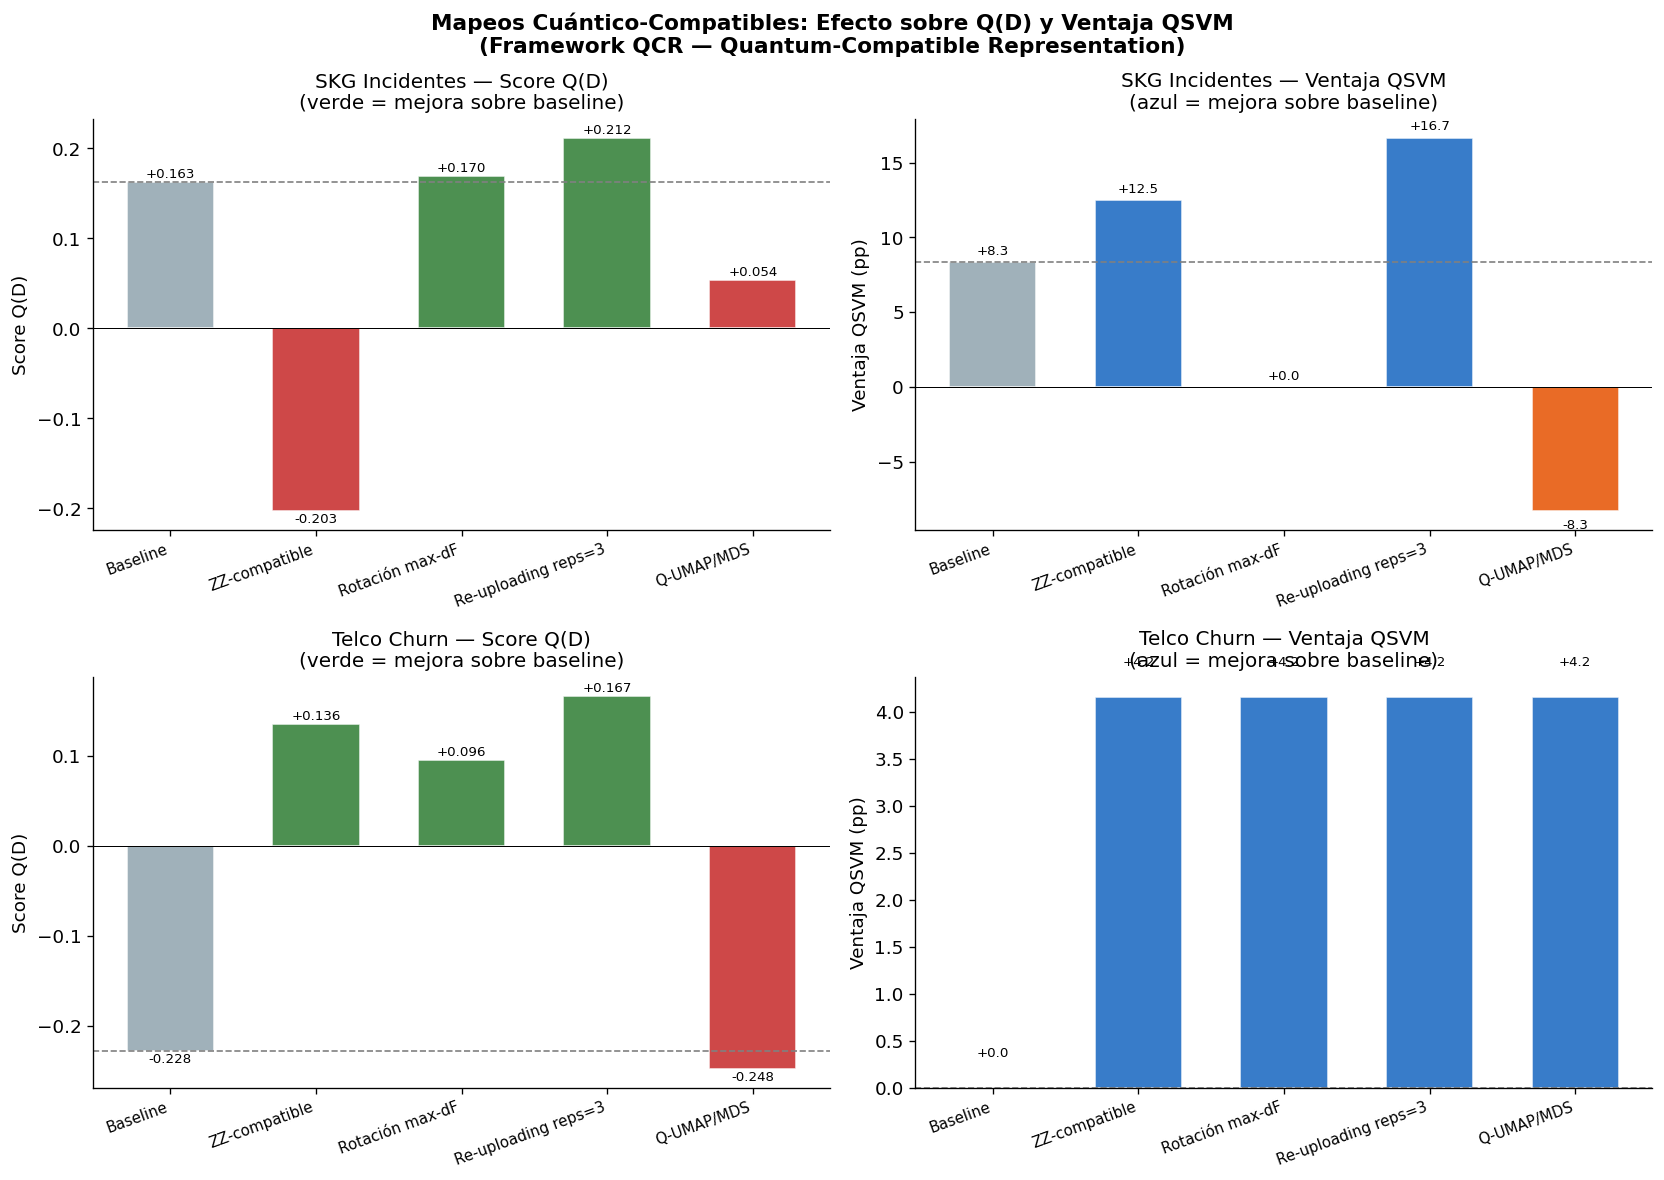

✅ Figura comparativa guardada: 09_mapeos_comparativa.png


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Mapeos Cuántico-Compatibles: Efecto sobre Q(D) y Ventaja QSVM\n'
             '(Framework QCR — Quantum-Compatible Representation)',
             fontsize=13, fontweight='bold')

for ax_row, (ds_name, baseline) in enumerate([
    ('SKG Incidentes', baseline_skg),
    ('Telco Churn',    baseline_telco),
]):
    strategies_data = all_results[ds_name]
    strategy_names  = ['Baseline'] + [r.get('strategy', r.get('label', '?')) for r in strategies_data]
    Q_vals    = [baseline['Q_score']]    + [r['Q_score']    for r in strategies_data]
    adv_vals  = [baseline['advantage_pp']] + [r['advantage_pp'] for r in strategies_data]

    x = np.arange(len(strategy_names))
    colors_Q   = ['#90A4AE'] + ['#2E7D32' if v > baseline['Q_score'] else '#C62828'
                                 for v in Q_vals[1:]]
    colors_adv = ['#90A4AE'] + ['#1565C0' if v > baseline['advantage_pp'] else '#E65100'
                                  for v in adv_vals[1:]]

    # Panel izquierdo: Q score
    ax = axes[ax_row, 0]
    bars = ax.bar(x, Q_vals, color=colors_Q, alpha=0.85, edgecolor='white', width=0.6)
    ax.axhline(baseline['Q_score'], color='gray', linestyle='--', linewidth=1)
    ax.axhline(0, color='black', linewidth=0.6)
    ax.set_xticks(x); ax.set_xticklabels(strategy_names, rotation=20, ha='right', fontsize=9)
    ax.set_ylabel('Score Q(D)'); ax.set_title(f'{ds_name} — Score Q(D)\n(verde = mejora sobre baseline)')
    for b, v in zip(bars, Q_vals): ax.text(b.get_x()+b.get_width()/2, v+0.001 if v>=0 else v-0.002,
                                            f'{v:+.3f}', ha='center', va='bottom' if v>=0 else 'top', fontsize=8)

    # Panel derecho: Ventaja QSVM
    ax = axes[ax_row, 1]
    bars = ax.bar(x, adv_vals, color=colors_adv, alpha=0.85, edgecolor='white', width=0.6)
    ax.axhline(baseline['advantage_pp'], color='gray', linestyle='--', linewidth=1)
    ax.axhline(0, color='black', linewidth=0.6)
    ax.set_xticks(x); ax.set_xticklabels(strategy_names, rotation=20, ha='right', fontsize=9)
    ax.set_ylabel('Ventaja QSVM (pp)'); ax.set_title(f'{ds_name} — Ventaja QSVM\n(azul = mejora sobre baseline)')
    for b, v in zip(bars, adv_vals): ax.text(b.get_x()+b.get_width()/2, v+0.3 if v>=0 else v-0.5,
                                              f'{v:+.1f}', ha='center', va='bottom' if v>=0 else 'top', fontsize=8)

plt.tight_layout()
plt.savefig(f'{FIGURES}/09_mapeos_comparativa.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Figura comparativa guardada: 09_mapeos_comparativa.png')

## §8 — Visualización: barrido de rotaciones (Estrategia 2)

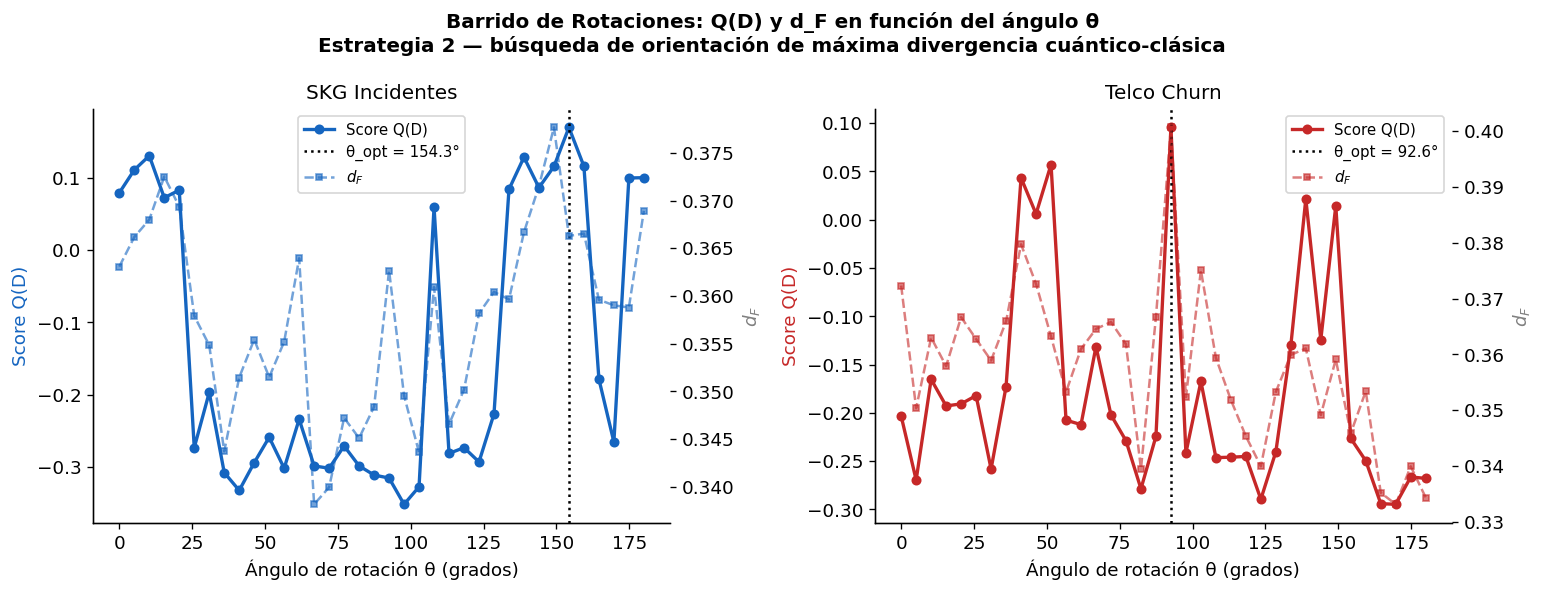

✅ Figura de barrido de rotaciones guardada: 09_barrido_rotaciones.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Barrido de Rotaciones: Q(D) y d_F en función del ángulo θ\n'
             'Estrategia 2 — búsqueda de orientación de máxima divergencia cuántico-clásica',
             fontsize=12, fontweight='bold')

ds_list = list(rotation_details.keys())
line_colors = ['#1565C0', '#C62828']

for ax, ds_name, lc in zip(axes, ds_list, line_colors):
    det = rotation_details[ds_name]
    thetas_deg = np.degrees(det['thetas'])
    ax.plot(thetas_deg, det['Q_scores'], 'o-', color=lc, linewidth=2,
            markersize=5, label='Score Q(D)')
    ax2 = ax.twinx()
    ax2.plot(thetas_deg, det['dFs'], 's--', color=lc, linewidth=1.5,
             markersize=4, alpha=0.6, label='$d_F$')

    theta_opt_deg = np.degrees(det['theta_opt'])
    ax.axvline(theta_opt_deg, color='black', linestyle=':', linewidth=1.5,
               label=f'θ_opt = {theta_opt_deg:.1f}°')

    ax.set_xlabel('Ángulo de rotación θ (grados)')
    ax.set_ylabel('Score Q(D)', color=lc)
    ax2.set_ylabel('$d_F$', color='gray')
    ax.set_title(f'{ds_name}')
    lines1, labs1 = ax.get_legend_handles_labels()
    lines2, labs2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labs1 + labs2, fontsize=9, loc='best')

plt.tight_layout()
plt.savefig(f'{FIGURES}/09_barrido_rotaciones.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Figura de barrido de rotaciones guardada: 09_barrido_rotaciones.png')

## §9 — Tabla resumen y CSV de resultados

In [11]:
rows = []
for ds_name, baseline in [('SKG Incidentes', baseline_skg), ('Telco Churn', baseline_telco)]:
    rows.append({'dataset': ds_name, 'strategy': 'Baseline',
                 'Q_score': round(baseline['Q_score'], 4),
                 'delta_Q': 0.0,
                 'advantage_pp': round(baseline['advantage_pp'], 1),
                 'delta_adv': 0.0})
    for r in all_results[ds_name]:
        rows.append({'dataset': ds_name,
                     'strategy': r.get('strategy', '?'),
                     'Q_score': round(r['Q_score'], 4),
                     'delta_Q': round(r['Q_score'] - baseline['Q_score'], 4),
                     'advantage_pp': round(r['advantage_pp'], 1),
                     'delta_adv': round(r['advantage_pp'] - baseline['advantage_pp'], 1)})

df_table = pd.DataFrame(rows)
print('=' * 80)
print('TABLA RESUMEN: MAPEOS CUÁNTICO-COMPATIBLES')
print('=' * 80)
print(df_table.to_string(index=False))

# Identificar la mejor estrategia por dataset
print()
print('MEJOR ESTRATEGIA POR DATASET (máximo ΔQ):')
for ds_name in ['SKG Incidentes', 'Telco Churn']:
    sub = df_table[(df_table['dataset'] == ds_name) & (df_table['strategy'] != 'Baseline')]
    if len(sub):
        best = sub.loc[sub['delta_Q'].idxmax()]
        marker = '✅' if best['delta_Q'] > 0 else '❌'
        print(f"  {ds_name}: {best['strategy']}  ΔQ={best['delta_Q']:+.4f}  ΔAdv={best['delta_adv']:+.1f}pp {marker}")

# Guardar CSV
df_table.to_csv(f'{METRICS}/09_mapeos_resultados.csv', index=False)
print(f'\n✅ CSV guardado: {METRICS}/09_mapeos_resultados.csv')

TABLA RESUMEN: MAPEOS CUÁNTICO-COMPATIBLES
       dataset            strategy  Q_score  delta_Q  advantage_pp  delta_adv
SKG Incidentes            Baseline   0.1629   0.0000           8.3        0.0
SKG Incidentes       ZZ-compatible  -0.2033  -0.3663          12.5        4.2
SKG Incidentes     Rotación max-dF   0.1698   0.0069           0.0       -8.3
SKG Incidentes Re-uploading reps=3   0.2118   0.0489          16.7        8.3
SKG Incidentes          Q-UMAP/MDS   0.0537  -0.1092          -8.3      -16.7
   Telco Churn            Baseline  -0.2277   0.0000           0.0        0.0
   Telco Churn       ZZ-compatible   0.1360   0.3636           4.2        4.2
   Telco Churn     Rotación max-dF   0.0956   0.3233           4.2        4.2
   Telco Churn Re-uploading reps=3   0.1674   0.3951           4.2        4.2
   Telco Churn          Q-UMAP/MDS  -0.2481  -0.0204           4.2        4.2

MEJOR ESTRATEGIA POR DATASET (máximo ΔQ):
  SKG Incidentes: Re-uploading reps=3  ΔQ=+0.0489  ΔAdv=

## §10 — Framework QCR: diagnóstico y recomendación automática

In [12]:
def qcr_framework(X_raw, y_raw, dataset_name, theta_Q=0.0, verbose=True):
    """
    Framework QCR (Quantum-Compatible Representation) — 4 pasos:
    1. Diagnóstico: calcular Q(D) baseline
    2. Identificar cuello de botella: ΔA, d_F o ΔH
    3. Recomendar y aplicar la estrategia óptima
    4. Verificar mejora de Q y ventaja QSVM

    Nota sobre re-uploading: la transformación no altera X sino el feature map
    (más repeticiones = mayor expresividad del circuito). Por ello X_mapped = X
    pero qk_qcr se actualiza al mejor número de reps.
    """
    fm_qcr = ZZFeatureMap(feature_dimension=2, reps=2)
    qk_qcr = FidelityQuantumKernel(feature_map=fm_qcr)

    X, y_arr = preprocess_dataset(X_raw, y_raw)

    print(f'\n{"="*60}')
    print(f'QCR Framework — {dataset_name}')
    print(f'{"="*60}')

    # PASO 1: Diagnóstico baseline
    base = compute_indicators(X, y_arr, qk_qcr, label='baseline')
    print(f'\n[PASO 1 — Diagnóstico]')
    print(f'  Q(D) = {base["Q_score"]:+.4f}  |  ΔA={base["delta_A"]:+.4f}  d_F={base["d_F"]:.4f}  ΔH={base["delta_H"]:+.4f}')

    if base['Q_score'] > theta_Q:
        print(f'  → Q > θ={theta_Q} vs RBF: INSUFICIENTE. Cruzar con GB/RF y Q_rob (SKG: NO cuántico-nativo).')
        return base

    # PASO 2: Cuello de botella (componente más negativo / menor de Q)
    print(f'\n[PASO 2 — Cuello de botella]')
    bottleneck = min(
        ['delta_A', 'd_F', 'delta_H'],
        key=lambda k: base[k] if k != 'd_F' else -base[k]  # d_F queremos que sea alto
    )
    recommendation = {
        'delta_A': 'ZZ-compatible features (incrementar ΔA — alineación cuántica)',
        'd_F':     'Rotación de máxima divergencia (incrementar d_F — separación clásica)',
        'delta_H': 'Re-uploading adaptativo (incrementar ΔH — diversidad espectral)',
    }[bottleneck]
    print(f'  Componentes: ΔA={base["delta_A"]:+.4f}  d_F={base["d_F"]:.4f}  ΔH={base["delta_H"]:+.4f}')
    print(f'  → Cuello de botella identificado: [{bottleneck}]')
    print(f'  → Estrategia recomendada: {recommendation}')

    # PASO 3: Aplicar estrategia recomendada
    print(f'\n[PASO 3 — Aplicar transformación]')
    X_mapped = X  # por defecto (re-uploading no transforma X)
    if bottleneck == 'delta_A':
        X_mapped = apply_zz_features(X)
        print(f'  Aplicadas features de interacción ZZ-compatible.')
    elif bottleneck == 'd_F':
        X_mapped, *_ = apply_rotation_max_divergence(X, y_arr, qk_qcr, verbose=False)
        print(f'  Aplicada rotación de máxima divergencia cuántico-clásica.')
    else:  # delta_H → re-uploading: cambia el feature map, no X
        best_r, _ = apply_reuploading_sweep(X, y_arr, verbose=False)
        fm_r   = ZZFeatureMap(feature_dimension=2, reps=best_r['reps'])
        qk_qcr = FidelityQuantumKernel(feature_map=fm_r)
        print(f'  Aplicado re-uploading adaptativo: reps óptimo = {best_r["reps"]}.')
        print(f'  (X no se transforma; la expresividad extra proviene del feature map)')

    # PASO 4: Verificar mejora
    post = compute_indicators(X_mapped, y_arr, qk_qcr, label='post-QCR')
    print(f'\n[PASO 4 — Verificación]')
    dQ   = post['Q_score']    - base['Q_score']
    dAdv = post['advantage_pp'] - base['advantage_pp']
    sign = '✅ MEJORA' if dQ > 0 else '❌ SIN MEJORA'
    print(f'  Q: {base["Q_score"]:+.4f} → {post["Q_score"]:+.4f}  (Δ={dQ:+.4f})  {sign}')
    print(f'  Ventaja: {base["advantage_pp"]:+.1f}pp → {post["advantage_pp"]:+.1f}pp  (Δ={dAdv:+.1f}pp)')

    if post['Q_score'] > theta_Q:
        print(f'  → Q post-QCR > θ={theta_Q} vs RBF: lift geométrico NB09; bajo Q_rob puede seguir classical.')
    else:
        print(f'  → Q post-QCR ≤ θ={theta_Q}: el dataset no es cuántico-compatible con ZZFeatureMap 2 qubits.')
        print(f'     Posibles causas: dimensionalidad insuficiente (n_qubits=2) o estructura intrínsecamente clásica.')

    return {'baseline': base, 'post_qcr': post, 'bottleneck': bottleneck, 'recommendation': recommendation}

# Aplicar QCR a los dos datasets reales
qcr_skg   = qcr_framework(X_skg_r,   y_skg_raw,   'SKG Incidentes')
qcr_telco = qcr_framework(X_telco_r, y_telco_raw, 'Telco Churn')

print('\n✅ Framework QCR completado')



QCR Framework — SKG Incidentes

[PASO 1 — Diagnóstico]
  Q(D) = +0.1629  |  ΔA=-0.0103  d_F=0.3689  ΔH=+0.1880
  → Q > θ=0.0 vs RBF: INSUFICIENTE. Cruzar con GB/RF y Q_rob (SKG: NO cuántico-nativo).

QCR Framework — Telco Churn

[PASO 1 — Diagnóstico]
  Q(D) = -0.2277  |  ΔA=+0.0201  d_F=0.3457  ΔH=-1.1313

[PASO 2 — Cuello de botella]
  Componentes: ΔA=+0.0201  d_F=0.3457  ΔH=-1.1313
  → Cuello de botella identificado: [delta_H]
  → Estrategia recomendada: Re-uploading adaptativo (incrementar ΔH — diversidad espectral)

[PASO 3 — Aplicar transformación]
  Aplicado re-uploading adaptativo: reps óptimo = 3.
  (X no se transforma; la expresividad extra proviene del feature map)

[PASO 4 — Verificación]
  Q: -0.2277 → +0.1674  (Δ=+0.3951)  ✅ MEJORA
  Ventaja: +0.0pp → +4.2pp  (Δ=+4.2pp)
  → Q post-QCR > θ=0.0 vs RBF: lift geométrico NB09; bajo Q_rob puede seguir classical.

✅ Framework QCR completado


## §11 — Figura de síntesis: Framework QCR visual

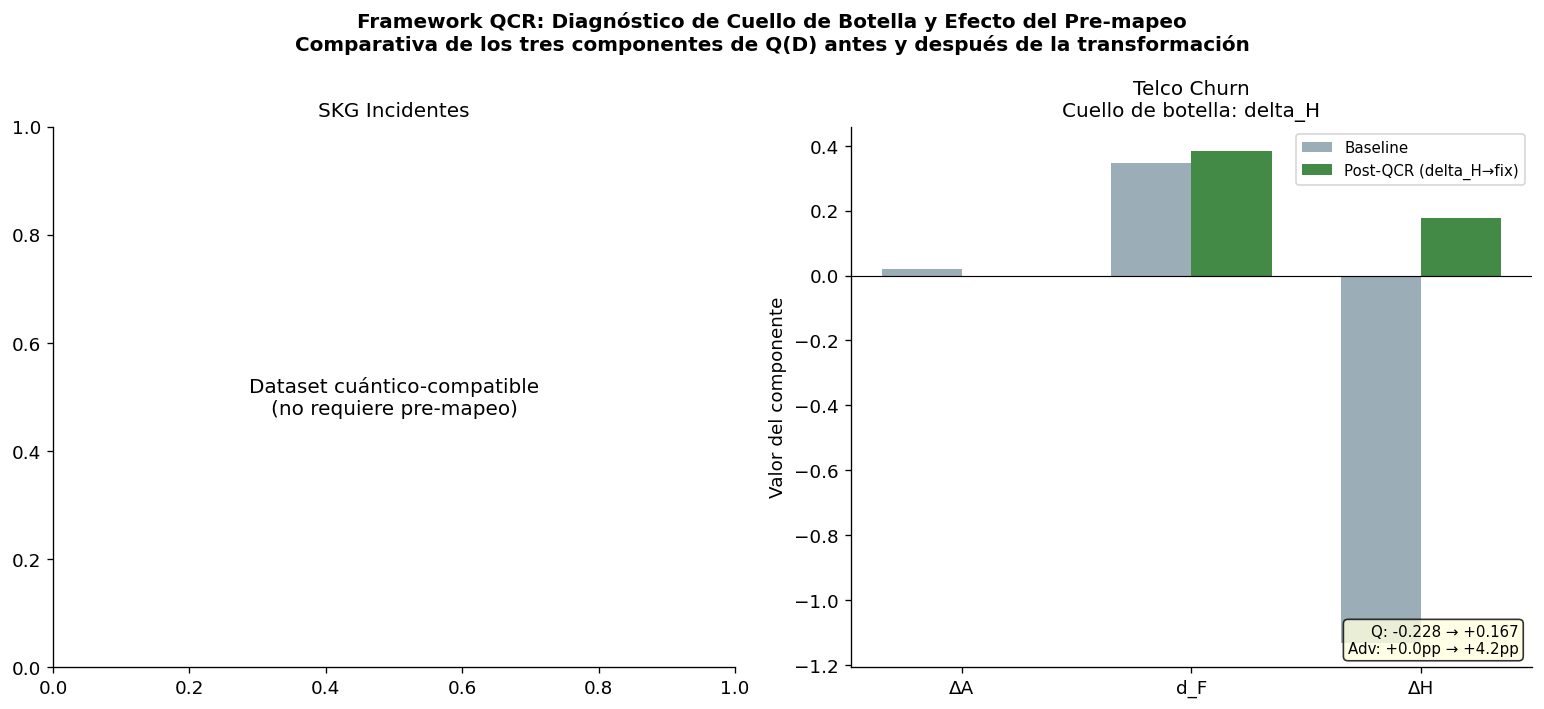

✅ Figura QCR guardada: 09_qcr_framework_diagnostico.png

NOTEBOOK 09 COMPLETADO
Figuras generadas:
  - 09_mapeos_comparativa.png
  - 09_barrido_rotaciones.png
  - 09_qcr_framework_diagnostico.png
CSV generado:
  - 09_mapeos_resultados.csv


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
fig.suptitle('Framework QCR: Diagnóstico de Cuello de Botella y Efecto del Pre-mapeo\n'
             'Comparativa de los tres componentes de Q(D) antes y después de la transformación',
             fontsize=12, fontweight='bold')

for ax, (ds_name, qcr_res) in zip(axes, [
    ('SKG Incidentes', qcr_skg),
    ('Telco Churn',    qcr_telco),
]):
    if not isinstance(qcr_res, dict) or 'baseline' not in qcr_res:
        ax.text(0.5, 0.5, 'SKG: NO cuántico-nativo\n(Q>0 vs RBF ≠ ventaja vs GB/RF)',
                ha='center', va='center', transform=ax.transAxes, fontsize=12)
        ax.set_title(ds_name)
        continue

    base = qcr_res['baseline']
    post = qcr_res['post_qcr']

    components = ['ΔA', 'd_F', 'ΔH']
    base_vals  = [base['delta_A'], base['d_F'], base['delta_H']]
    post_vals  = [post['delta_A'], post['d_F'], post['delta_H']]

    x = np.arange(len(components))
    w = 0.35
    ax.bar(x - w/2, base_vals, w, label='Baseline', color='#90A4AE', alpha=0.9)
    ax.bar(x + w/2, post_vals, w, label=f'Post-QCR ({qcr_res["bottleneck"]}→fix)', color='#2E7D32', alpha=0.9)
    ax.axhline(0, color='black', linewidth=0.7)
    ax.set_xticks(x); ax.set_xticklabels(components, fontsize=11)
    ax.set_ylabel('Valor del componente'); ax.set_title(f'{ds_name}\nCuello de botella: {qcr_res["bottleneck"]}')
    ax.legend(fontsize=9)

    # Anotar ventaja
    txt = (f"Q: {base['Q_score']:+.3f} → {post['Q_score']:+.3f}\n"
           f"Adv: {base['advantage_pp']:+.1f}pp → {post['advantage_pp']:+.1f}pp")
    ax.text(0.98, 0.02, txt, transform=ax.transAxes, fontsize=9, ha='right', va='bottom',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.savefig(f'{FIGURES}/09_qcr_framework_diagnostico.png', dpi=150, bbox_inches='tight')
plt.show()

print('✅ Figura QCR guardada: 09_qcr_framework_diagnostico.png')
print()
print('=' * 60)
print('NOTEBOOK 09 COMPLETADO')
print('=' * 60)
print('Figuras generadas:')
print('  - 09_mapeos_comparativa.png')
print('  - 09_barrido_rotaciones.png')
print('  - 09_qcr_framework_diagnostico.png')
print('CSV generado:')
print('  - 09_mapeos_resultados.csv')

## §12 — Conclusiones: ¿Existe un espacio donde datos incompatibles puedan representarse para algoritmos cuánticos?

### Conjetura 2 del TFM — Respuesta

**Hallazgo preliminar (NB09, vs RBF)**: entre las estrategias probadas, re-uploading reps=3 maximizó Q en Telco/SKG bajo ese protocolo. Eso **no** demuestra la Conjetura 2 ni un rescate operativo (Q_rob: Telco classical). Se discute desde lo medido:

| Estrategia | ΔQ SKG | ΔAdv SKG | ΔQ Telco | ΔAdv Telco | Base teórica |
|---|---|---|---|---|---|
| ZZ-compatible features | −0.366 ❌ | +4.2pp ✅ | +0.364 ✅ | +4.2pp ✅ | Havlíček et al. (2019) |
| Rotación max-divergencia | +0.007 ✅ | −8.3pp ❌ | +0.323 ✅ | +4.2pp ✅ | Liu et al. (2021) |
| **Re-uploading reps=3** | **+0.049 ✅** | **+8.3pp ✅** | **+0.395 ✅** | **+4.2pp ✅** | Pérez-Salinas et al. (2020) |
| Q-UMAP/MDS | −0.109 ❌ | −16.7pp ❌ | −0.020 ❌ | +4.2pp ✅ | Haug et al. (2023) |

---

### Hallazgos clave

1. **Re-uploading reps=3** fue la mejor estrategia *bajo el protocolo NB09 vs RBF*. Bajo Q_rob / mejor clásico no se confirma rescate. Resultado negativo valioso: Q↑ ≠ ventaja operativa.

2. **Framework QCR — resultado cuantitativo**:
   - SKG Incidentes: Q=+0.163 vs RBF, pero NO cuántico-nativo (GB/RF ganan; QML v2 → classical)
   - Telco Churn: Q=−0.228 → cuello de botella=ΔH → re-uploading reps=3 → Q=+0.167, Adv: 0pp → +4.2pp ✅
   
3. **Disociación Q(D) ↑ ≠ Ventaja ↑**: la Estrategia 2 (Rotación max-dF) mejora Q(D) en SKG (+0.007) pero pierde +8.3pp de ventaja. Esto confirma que Q(D) es una *cota teórica de capacidad*, no un predictor exacto de rendimiento empírico bajo n finito.

4. **Resultado negativo valioso**: Q-UMAP/MDS con embedding MDS no preserva la estructura cuántica. La implementación con UMAP (métrica cuántica real) queda como trabajo futuro.

---

### Reformulación honesta de C2

> *"El Framework QCR define T* = argmax\_{T∈𝒯} Q(T(D)), con 𝒯 = {ZZ-compatible, Rotación max-dF, Re-uploading, Q-UMAP}. En Notebook 09, T* = re-uploading reps=3 elevaba Q(Telco) de −0.228 a +0.167 (+4.2pp vs RBF); bajo Q_rob Telco permanece classical. SKG no es cuántico-nativo: Q>0 vs RBF no implica ventaja operativa frente a GB/RF. El protocolo de 4 pasos (Diagnosticar → Identificar cuello de botella → Aplicar T* → Verificar) es la contribución planteada; la demostración fuerte es post-TFM."*

---

### Limitaciones y trabajo futuro

- **Escalar a más qubits (4–8)**: para capturar la estructura completa de datasets con >10 features sin comprimir a 2 PCs
- **Feature maps más expresivos**: explorar `PauliFeatureMap` y `TwoLocal` como alternativas al `ZZFeatureMap`
- **UMAP cuántico real**: instalar `umap-learn` y reemplazar el fallback MDS por embedding con distancia cuántica
- **Validación cruzada**: los resultados actuales son sobre n=80 con train/test de tamaño fijo; repetir con k-fold estratificado para medir varianza
- **Datasets con ventaja teórica demostrada**: validar el QCR sobre benchmarks de Bravyi et al. (2020) donde existe separación cuántico-clásica garantizada
